# Resonant Magnetic X-ray Scattering

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/07-xray_reflectivity/01-resonant_magnetic_xray.ipynb)

In this example the static and transient resonant magnetic X-ray reflectivity of an antiferromagnetic Fe/Cr superlattice at the Fe $L_3$ edge is calculated by the multilayer formalism of {py:class}`Elzo <udkm1Dsim.simulations.scattering.elzo.Elzo>`, which was adapted from [Dyna](http://dyna.neel.cnrs.fr), see the [scattering overview](#example_scattering_overview).
The transient strain and magnetization of the superlattice follow from the heat, phonon, and magnetization simulations after an optical excitation.

:::{admonition} Reference {cite}`elzo2012`
:class: seealso
M. Elzo, et al., *X-ray resonant magnetic reflectivity of stratified magnetic structures: Eigenwave formalism and application to a W/Fe/W trilayer*, [J. Magn. Magn. Mater. 324, 105 (2012)](http://www.doi.org/10.1016/j.jmmm.2011.07.019)
:::

## Setup

Do all necessary imports and settings.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim[parallel]
    import udkm1Dsim as ud

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

## Structure

Refer to the [structure example](#example_structure) for more details.

The antiferromagnetic superlattice is built of {py:class}`AmorphousLayer <udkm1Dsim.structures.layers.AmorphousLayer>`s, where two types of Fe atoms with opposite in-plane magnetization along $y$ form the antiparallel Fe layers.
The atomic form factor of Fe is read from a local file.
The heat is described by a two-temperature model of the electrons and phonons as in the [LLB example](#example_LLB).

In [2]:
# opposite cartesian in-plane magnetizations along y
Fe_right = ud.Atom("Fe", magnetization=(0, 1, 0), atomic_form_factor_path="./Fe.cf")
Fe_left = ud.Atom("Fe", magnetization=(0, -1, 0), atomic_form_factor_path="./Fe.cf")
Cr = ud.Atom("Cr")
Si = ud.Atom("Si")

In [3]:
# both Fe layers are built from the same parameter groups, which are copied for every layer
structural_Fe = ud.StructuralParameters(thickness=1 * u.nm, density=7874 * u.kg / u.m**3)
# two-temperature model of the electrons and phonons
thermal_Fe = ud.ThermalParameters(
    heat_capacity=["0.085*T", 450 * u.J / (u.kg * u.K)],
    therm_cond=[80 * u.W / (u.m * u.K), 5 * u.W / (u.m * u.K)],
    sub_system_coupling=["-7e17*(T_0-T_1)", "7e17*(T_0-T_1)"],
    lin_therm_exp=[0, 11.8e-6 / u.K],
    sub_system_labels=["e", "p"],
)
elastic_Fe = ud.ElasticParameters(sound_vel=4.910 * u.nm / u.ps)
optical_Fe = ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(2.9174 + 3.3545j))
# mean-field parameters, the magnetization is set by the Fe atoms
magnetic_Fe = ud.MagneticParameters(eff_spin=2, curie_temp=1044 * u.K)

layer_Fe_left = ud.AmorphousLayer(
    "Fe_left",
    "Fe left amorphous",
    atom=Fe_left,
    structural=structural_Fe,
    thermal=thermal_Fe,
    elastic=elastic_Fe,
    optical=optical_Fe,
    magnetic=magnetic_Fe,
)
layer_Fe_right = ud.AmorphousLayer(
    "Fe_right",
    "Fe right amorphous",
    atom=Fe_right,
    structural=structural_Fe,
    thermal=thermal_Fe,
    elastic=elastic_Fe,
    optical=optical_Fe,
    magnetic=magnetic_Fe,
)

In [4]:
layer_Cr = ud.AmorphousLayer(
    "Cr",
    "Cr amorphous",
    atom=Cr,
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=7140 * u.kg / u.m**3),
    thermal=ud.ThermalParameters(
        heat_capacity=["0.03*T", 449 * u.J / (u.kg * u.K)],
        therm_cond=[90 * u.W / (u.m * u.K), 5 * u.W / (u.m * u.K)],
        sub_system_coupling=["-5e17*(T_0-T_1)", "5e17*(T_0-T_1)"],
        lin_therm_exp=[0, 6.2e-6 / u.K],
        sub_system_labels=["e", "p"],
    ),
    elastic=ud.ElasticParameters(sound_vel=5.940 * u.nm / u.ps),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(3.1612 + 3.4606j)),
)

In [5]:
# Si is not metallic
layer_Si = ud.AmorphousLayer(
    "Si",
    "Si amorphous",
    atom=Si,
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=2336 * u.kg / u.m**3),
    thermal=ud.ThermalParameters(
        heat_capacity=[100 * u.J / (u.kg * u.K), 603 * u.J / (u.kg * u.K)],
        therm_cond=[0, 150 * u.W / (u.m * u.K)],
        sub_system_coupling=[0, 0],
        lin_therm_exp=[0, 2.6e-6 / u.K],
        sub_system_labels=["e", "p"],
    ),
    elastic=ud.ElasticParameters(sound_vel=8.433 * u.nm / u.ps),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(3.6941 + 0.0065435j)),
)

The refractive indices above are only valid in the optical range, i.e. for the excitation at 800 nm.
In the X-ray range, the dielectric functions of the layers follow from the atomic and magnetic form factors of their atoms, which are set by {py:meth}`set_dielectric_from_atoms() <udkm1Dsim.structures.layers.Layer.set_dielectric_from_atoms>` with the refractive indices as fallback, see the [dielectric example](#example_dielectric):

In [6]:
# the refractive indices above are kept as fallback outside of the form factors
for layer in [layer_Fe_left, layer_Fe_right, layer_Cr, layer_Si]:
    layer.set_dielectric_from_atoms(fallback=layer.dielectric.eps0)

layer_Fe_left.optical

Optical Parameters
╔═════════════╦══════════╦═══════════════════════════════════════════════════════════════════════════╦════════╗
║ Parameter   ║  Symbol  ║                                                                     Value ║ Unit   ║
╠═════════════╬══════════╬═══════════════════════════════════════════════════════════════════════════╬════════╣
║ dielectric  ║    ε⁰    ║ atomic form factors of Fe from 12.93 eV to 432.9 keV | n = 2.917 + 3.354i ║        ║
║             ║    εᵐ    ║                         magnetic form factors of Fe from 31 eV to 100 keV ║        ║
║             ║   s(η)   ║                                                     1/(1+η) for ε⁰ and εᵐ ║        ║
╚═════════════╩══════════╩═══════════════════════════════════════════════════════════════════════════╩════════╝

In [7]:
S = ud.Structure("Fe/Cr AFM Super Lattice")

# create a sub-structure
DL = ud.Structure("Two Fe/Cr Double Layers")
DL.add_sub_structure(layer_Fe_left, 1)
DL.add_sub_structure(layer_Cr, 1)
DL.add_sub_structure(layer_Fe_right, 1)
DL.add_sub_structure(layer_Cr, 1)

S.add_sub_structure(DL, 10)
S.add_sub_structure(layer_Fe_left, 10)
S.add_sub_structure(layer_Si, 200)

# add semi-infinite, static substrate
S.add_substrate(layer_Si)

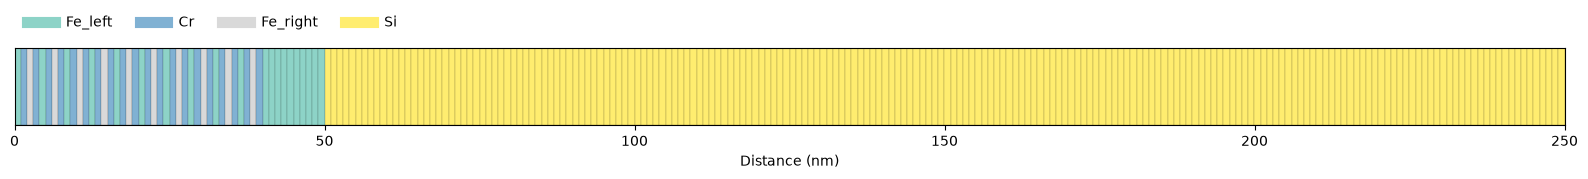

Structure properties:

Name   : Fe/Cr AFM Super Lattice
Thickness : 250 nm
----
sub-structure 10 times:
	Structure properties:

	Name   : Two Fe/Cr Double Layers
	Thickness : 4 nm
	----
	1 times Fe left amorphous: 1 nm
	1 times Cr amorphous: 1 nm
	1 times Fe right amorphous: 1 nm
	1 times Cr amorphous: 1 nm
	----
10 times Fe left amorphous: 10 nm
200 times Si amorphous: 200 nm
----
Superstrate (semi-infinite):
----
1 times vacuum: 1 nm
----
Substrate (semi-infinite):
----
1 times Si amorphous: 1 nm

In [8]:
S.visualize()
S

## Heat

Refer to the [excitation & NTM example](#example_excitation_NTM) for more details.

In [9]:
h = ud.Heat(S, True)

h.save_data = False
h.disp_messages = True

h.excitation = {
    "fluence": [40] * u.mJ / u.cm**2,
    "delay_pump": [0] * u.ps,
    "pulse_width": [1] * u.ps,
    "multilayer_absorption": True,
    "wavelength": 800 * u.nm,
    "theta": 45 * u.deg,
}

# enable heat diffusion
h.heat_diffusion = True

# temporal and spatial grid
delays = np.r_[-2:40:0.1] * u.ps
_, _, distances = S.get_distances_of_layers()

In [10]:
res_temp = h.get_temp_map(delays, 300 * u.K)
res_temp

Surface incidence fluence scaled by factor 0.7071 due to incidence angle theta=45.00 deg
Calculating _heat_diffusion_ for excitation 1:1 ...
Absorption profile is calculated by multilayer formalism with p-polarization.
Total reflectivity of 47.7 % and transmission of 6.3 %.


0it [00:00, ?it/s]

Elapsed time for _heat_diffusion_ with 1 excitation(s): 0.340022 s
Calculating _heat_diffusion_ without excitation...


0it [00:00, ?it/s]

Elapsed time for _heat_diffusion_: 0.200282 s
Elapsed time for _temp_map_: 0.724606 s


name,alias,kind,shape,dims,unit
temp_map,,data,"(420, 250, 2)","delays, distances, subsystems",K
delta_temp_map,,data,"(420, 250, 2)","delays, distances, subsystems",K
init_temp,,data,"(250, 2)","distances, subsystems",K
delays,,coord,"(420,)",delays,s
distances,,coord,"(250,)",distances,m


The heat simulation returns its result as a {py:class}`Result <udkm1Dsim.simulations.result.Result>` with the `temp_map` and `delta_temp_map` and their coordinates, here named `res_temp`, which is passed on to the following simulations as a whole, see the [simulations and results example](#example_simulations_and_results).

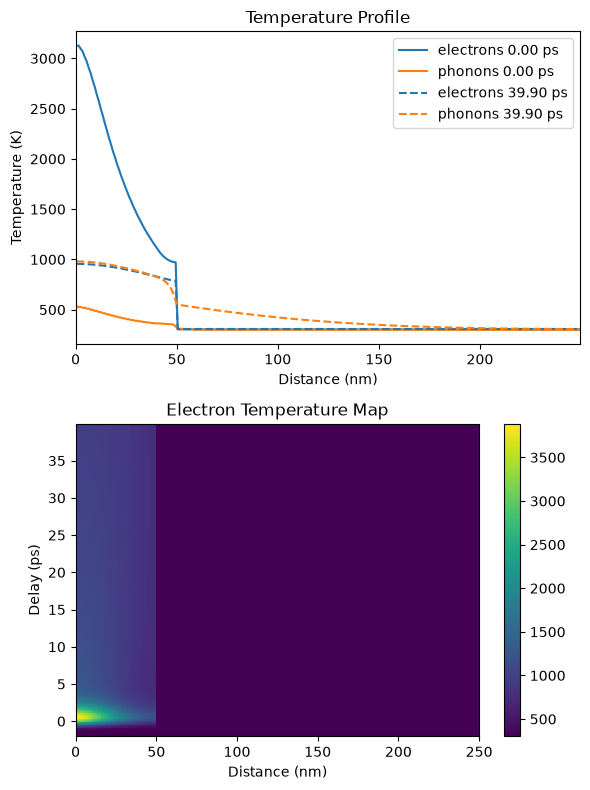

In [11]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
for i, style in ((20, "-"), (-1, "--")):
    for k, label in enumerate(["electrons", "phonons"]):
        plt.plot(
            distances.to("nm").magnitude,
            res_temp.temp_map[i, :, k],
            style,
            color=f"C{k}",
            label="{:s} {:0.2f} ps".format(label, delays[i].to("ps").magnitude),
        )
plt.xlim([0, distances.to("nm").magnitude[-1]])
plt.xlabel("Distance (nm)")
plt.ylabel("Temperature (K)")
plt.legend()
plt.title("Temperature Profile")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    distances.to("nm").magnitude,
    delays.to("ps").magnitude,
    res_temp.temp_map[:, :, 0],
    shading="auto",
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Electron Temperature Map")

plt.tight_layout()
plt.show()

## Numerical Phonons

Refer to the [strain pulse example](#example_strain_pulses) for more details.

In [12]:
p = ud.PhononNum(S, True)
p.save_data = False
p.disp_messages = True

In [13]:
res_strain = p.get_strain_map(delays, res_temp)

Calculating linear thermal expansion ...
Calculating coherent dynamics with ODE solver ...


0it [00:00, ?it/s]

Elapsed time for _strain_map_: 0.314065 s


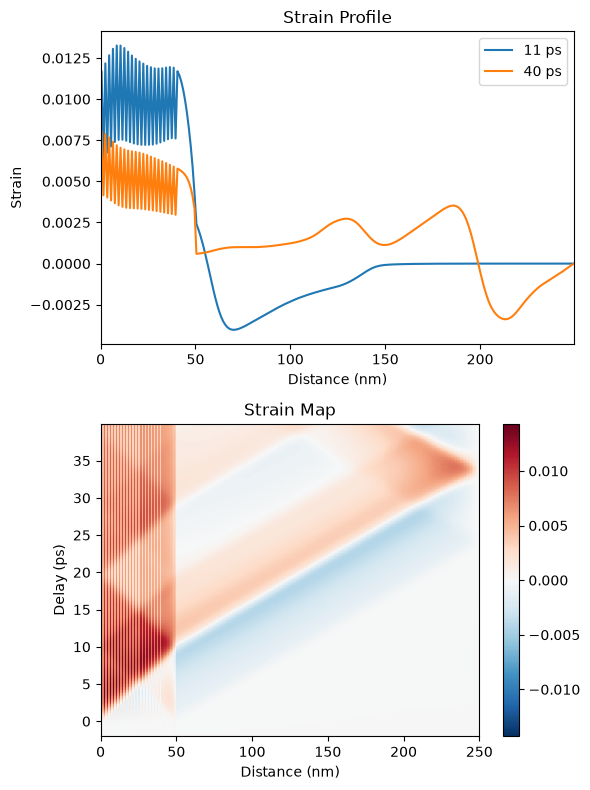

In [14]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
plt.plot(distances.to("nm").magnitude, res_strain.strain_map[130, :], label=np.round(delays[130]))
plt.plot(distances.to("nm").magnitude, res_strain.strain_map[-1, :], label=np.round(delays[-1]))
plt.xlim([0, distances.to("nm").magnitude[-1]])
plt.xlabel("Distance (nm)")
plt.ylabel("Strain")
plt.legend()
plt.title("Strain Profile")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    distances.to("nm").magnitude,
    delays.to("ps").magnitude,
    res_strain.strain_map,
    cmap="RdBu_r",
    vmin=-np.max(res_strain.strain_map),
    vmax=np.max(res_strain.strain_map),
    shading="auto",
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Strain Map")

plt.tight_layout()
plt.show()

## Magnetization

Refer to the [LLG example](#example_LLG) for more details.

Here, the magnetization amplitude follows the mean-field magnetization $m_\mathrm{eq}(T_e)$ of the electron temperature as a simplified model, which is given by the `eff_spin` and `curie_temp` of the {py:class}`MagneticParameters <udkm1Dsim.structures.parameter_groups.MagneticParameters>` of the Fe layers, see {py:meth}`get_mean_field_mag_map <udkm1Dsim.simulations.magnetization.Magnetization.get_mean_field_mag_map>`.
The cartesian `magnetization_map` $(m_x, m_y, m_z)$ is the mean-field magnetization times the direction of the magnetization of every layer.

:::{note}
This *adiabatic limit* assumes that the magnetization follows the temperature instantaneously, otherwise the [LLB](#example_LLB) is required.
:::

In [15]:
mag = ud.Magnetization(S, True)
mag.save_data = False
mag.disp_messages = True

# mean-field magnetization of the electron temperature of the temp_sub_system 0
res_mf = mag.get_mean_field_mag_map(res_temp)
# cartesian direction of the magnetization of every layer
_, _, handles = S.get_layer_vectors()
directions = np.array([handle.magnetization.magnitude for handle in handles])
magnetization_map = res_mf.mf_mag_map[:, :, np.newaxis] * directions[np.newaxis, :, :]

Calculating _mf_magnetization_map_ ...
Elapsed time for _mf_magnetization_map_: 0.099683 s


Calculating _mf_magnetization_map_ ...
Elapsed time for _mf_magnetization_map_: 0.120484 s


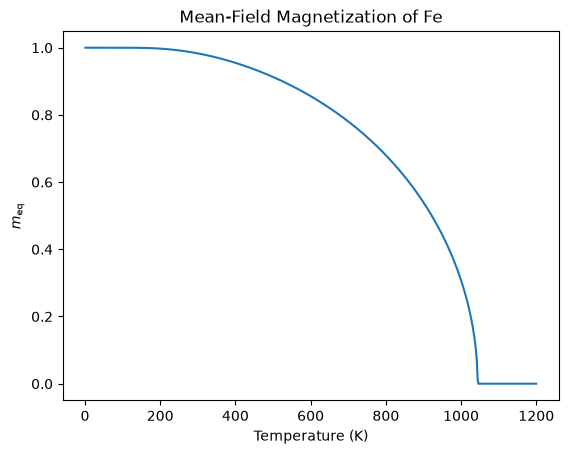

In [16]:
temperatures = np.linspace(1, 1200, 600)
temp_map_mf = np.tile(temperatures[:, np.newaxis], (1, S.get_number_of_layers()))
mf_mag_map = mag.get_mean_field_mag_map(temp_map_mf).mf_mag_map
select_Fe = S.get_all_positions_per_unique_layer()["Fe_left"]

plt.figure()
plt.plot(temperatures, mf_mag_map[:, select_Fe[0]])
plt.xlabel("Temperature (K)")
plt.ylabel("$m_\\mathrm{eq}$")
plt.title("Mean-Field Magnetization of Fe")
plt.show()

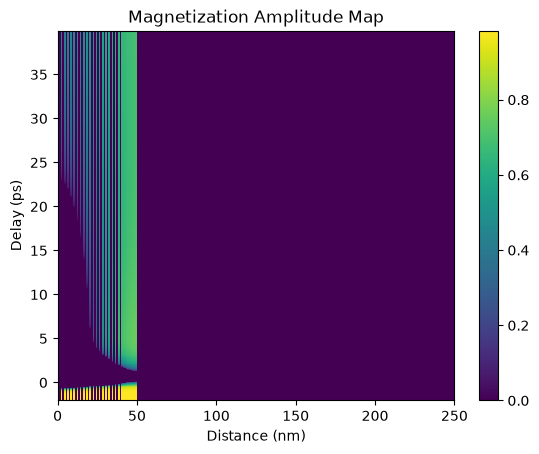

In [17]:
plt.figure()
plt.pcolormesh(
    distances.to("nm").magnitude,
    delays.to("ps").magnitude,
    np.linalg.norm(magnetization_map, axis=-1),
    shading="auto",
)
plt.title("Magnetization Amplitude Map")
plt.ylabel("Delay (ps)")
plt.xlabel("Distance (nm)")
plt.colorbar()
plt.show()

## Resonant Magnetic X-ray Reflectivity

The {py:class}`Elzo <udkm1Dsim.simulations.scattering.elzo.Elzo>` simulation is initialized as all other simulations, see the [scattering overview](#example_scattering_overview) for its experiment parameters and polarizations.

:::{note}
The formalism of {cite:t}`elzo2012` was formerly called `XrayDynMag`, which was removed in version 3.0.0.
:::

In [18]:
dyn_mag = ud.Elzo(S, True)
dyn_mag.disp_messages = True
dyn_mag.save_data = False

## Homogeneous Magnetic X-ray Reflectivity

For homogeneously strained and magnetized sub-structures, the simulations are greatly simplified, which saves a lot of computational time.

### $q_z$-scan

The reflectivity has a first dimension for the photon energies and a second for the scattering vectors $q_z$.
It is calculated for the actual magnetization (`reflectivity` or its alias `R`) of the sample and for the opposite magnetization (`reflectivity_phi` or `R_phi`), which are returned together with the coordinates `energy`, `qz`, and `theta` of the experiment.

In [19]:
dyn_mag.energy = np.r_[600, 708] * u.eV  # set two photon energies
dyn_mag.qz = np.r_[0.01:5:0.01] / u.nm  # qz range
# this is the actual calculation
res_hom = dyn_mag.homogeneous_reflectivity_transmissivity()
res_hom

Calculating _homogeneous_reflectivity_transmissivity_ ...
Elapsed time for _homogeneous_reflectivity_transmissivity_: 0.031434 s


name,alias,kind,shape,dims,unit
reflectivity,R,data,"(2, 499)","energy, angles",
reflectivity_phi,R_phi,data,"(2, 499)","energy, angles",
transmissivity,T,data,"(2, 499)","energy, angles",
transmissivity_phi,T_phi,data,"(2, 499)","energy, angles",
energy,,coord,"(2,)",energy,eV
qz,,coord,"(2, 499)","energy, angles",1/nm
theta,,coord,"(2, 499)","energy, angles",deg


In this example half-order antiferromagnetic Bragg peaks appear only at the resonance.

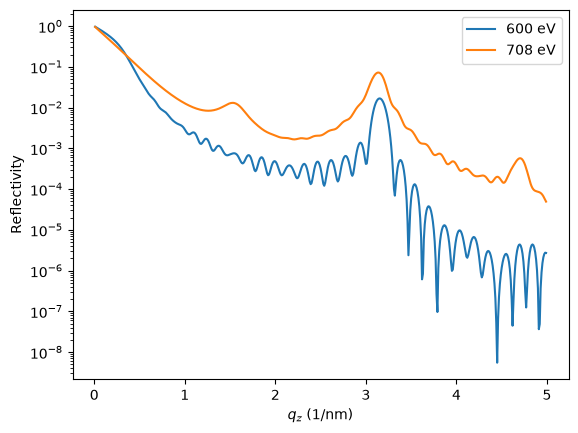

In [20]:
plt.figure()
for i in range(2):
    plt.semilogy(res_hom.qz[i, :], res_hom.R[i, :], label=f"{res_hom.energy[i]:.0f} eV")
plt.ylabel("Reflectivity")
plt.xlabel(r"$q_z$ (1/nm)")
plt.legend()
plt.show()

### Post-Processing

Simple convolution of the results with an arbitrary function handle.

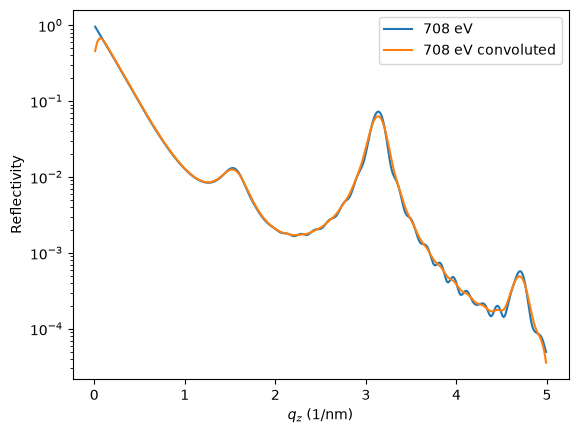

In [21]:
FWHM = 0.01 / 1e-10  # Angstrom
sigma = FWHM / 2.3548

handle = lambda x: np.exp(-(((x) / sigma) ** 2) / 2)
y_conv = dyn_mag.conv_with_function(res_hom.R[1, :], dyn_mag.experiment.qz.magnitude[1, :], handle)

plt.figure()
plt.semilogy(dyn_mag.qz[0, :], res_hom.R[1, :], label=f"{dyn_mag.energy[1]}")
plt.semilogy(dyn_mag.qz[0, :], y_conv, label=f"{dyn_mag.energy[1]} convoluted")
plt.ylabel("Reflectivity")
plt.xlabel(r"$q_z$ (1/nm)")
plt.legend()
plt.show()

### Energy- and $q_z$-scan

In [22]:
dyn_mag.energy = np.r_[690:730:0.1] * u.eV  # set the energy range
dyn_mag.qz = np.r_[0.01:5:0.01] / u.nm  # qz range
# this is the actual calculation
res_gallery = dyn_mag.homogeneous_reflectivity_transmissivity()

Calculating _homogeneous_reflectivity_transmissivity_ ...
Elapsed time for _homogeneous_reflectivity_transmissivity_: 4.628582 s


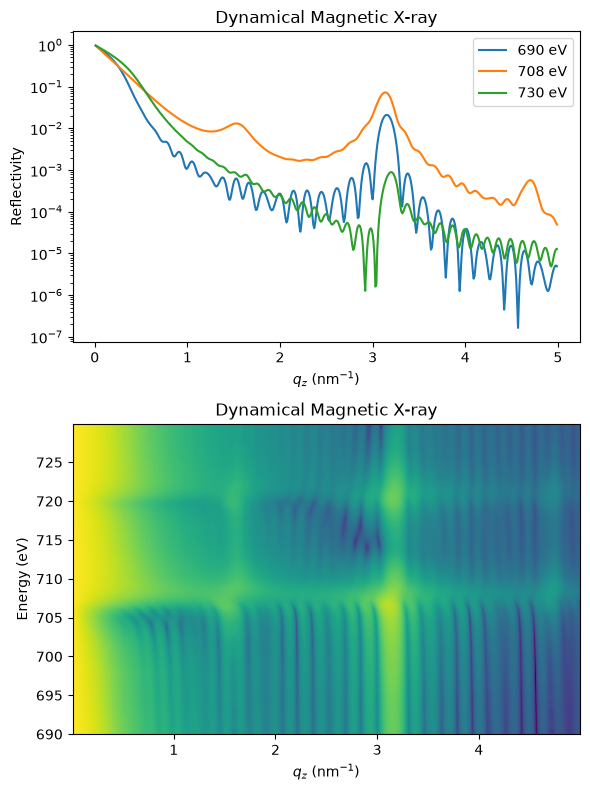

In [23]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
plt.semilogy(dyn_mag.qz[0, :].to("1/nm"), res_gallery.R[0, :], label=np.round(dyn_mag.energy[0]))
plt.semilogy(
    dyn_mag.qz[0, :].to("1/nm"),
    res_gallery.R[180, :],
    label=np.round(dyn_mag.energy[180]),
)
plt.semilogy(
    dyn_mag.qz[0, :].to("1/nm"),
    res_gallery.R[-1, :],
    label=np.round(dyn_mag.energy[-1]),
)

plt.xlabel("$q_z$ (nm$^{-1}$)")
plt.ylabel("Reflectivity")
plt.legend()
plt.title("Dynamical Magnetic X-ray")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    dyn_mag.qz[0, :].to("1/nm").magnitude,
    dyn_mag.energy.magnitude,
    np.log10(res_gallery.R[:, :]),
    shading="auto",
)
plt.title("Dynamical Magnetic X-ray")
plt.ylabel("Energy (eV)")
plt.xlabel("$q_z$ (nm$^{-1}$)")

plt.tight_layout()
plt.show()

### Polarization Dependence

The incoming and analyzer polarizations are set by their names or ids, see the [polarizations in the scattering overview](#example_scattering_overview).
Here, the reflectivity of $\sigma$-polarized light is compared without analyzer and for the $\sigma$ and $\pi$ analyzer.

incoming polarizations set to: sigma
analyzer polarizations set to: unpolarized
Calculating _homogeneous_reflectivity_transmissivity_ ...
Elapsed time for _homogeneous_reflectivity_transmissivity_: 0.012239 s
incoming polarizations set to: sigma
analyzer polarizations set to: sigma
Calculating _homogeneous_reflectivity_transmissivity_ ...
Elapsed time for _homogeneous_reflectivity_transmissivity_: 0.011434 s
incoming polarizations set to: sigma
analyzer polarizations set to: pi
Calculating _homogeneous_reflectivity_transmissivity_ ...
Elapsed time for _homogeneous_reflectivity_transmissivity_: 0.017317 s


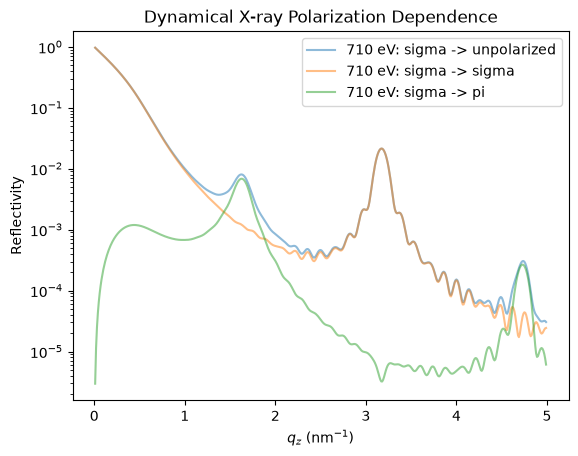

In [24]:
dyn_mag.energy = np.r_[710] * u.eV
dyn_mag.qz = np.r_[0.01:5:0.01] / u.nm  # qz range

plt.figure()
dyn_mag.set_polarization("sigma", "none")
R_hom = dyn_mag.homogeneous_reflectivity_transmissivity().R
plt.semilogy(
    dyn_mag.qz[0, :], R_hom[0, :], label=f"{dyn_mag.energy[0]}: sigma -> unpolarized", alpha=0.5
)

dyn_mag.set_polarization("sigma", "sigma")
R_hom = dyn_mag.homogeneous_reflectivity_transmissivity().R
plt.semilogy(
    dyn_mag.qz[0, :], R_hom[0, :], label=f"{dyn_mag.energy[0]}: sigma -> sigma", alpha=0.5
)

dyn_mag.set_polarization("sigma", "pi")
R_hom = dyn_mag.homogeneous_reflectivity_transmissivity().R
plt.semilogy(dyn_mag.qz[0, :], R_hom[0, :], label=f"{dyn_mag.energy[0]}: sigma -> pi", alpha=0.5)

plt.xlabel("$q_z$ (nm$^{-1}$)")
plt.ylabel("Reflectivity")
plt.title("Dynamical X-ray Polarization Dependence")
plt.legend()
plt.show()

## Inhomogeneous Magnetic X-ray Reflectivity

The {py:meth}`inhomogeneous_reflectivity_transmissivity <udkm1Dsim.simulations.scattering.elzo.Elzo.inhomogeneous_reflectivity_transmissivity>` method calculates the transient magnetic X-ray reflectivity for the `strain_map` and the cartesian `magnetization_map` of every layer.
The result of the phonon simulation is passed on as `strain_map`, so that the reflectivity also holds its `delays`.

In [25]:
dyn_mag.energy = np.r_[708] * u.eV  # set the energy range
dyn_mag.qz = np.r_[1:3.5:0.01] / u.nm  # qz range
dyn_mag.set_polarization("sigma", "none")

incoming polarizations set to: sigma
analyzer polarizations set to: unpolarized


In [26]:
res_inhom = dyn_mag.inhomogeneous_reflectivity_transmissivity(
    strain_map=res_strain, magnetization_map=magnetization_map
)

Calculating _inhomogeneous_reflectivity_transmissivity_Elzo_ ...


Progress:   0%|          | 0/420 [00:00<?, ?it/s]

Elapsed time for _inhomogeneous_reflectivity_transmissivity_Elzo_: 71.584892 s


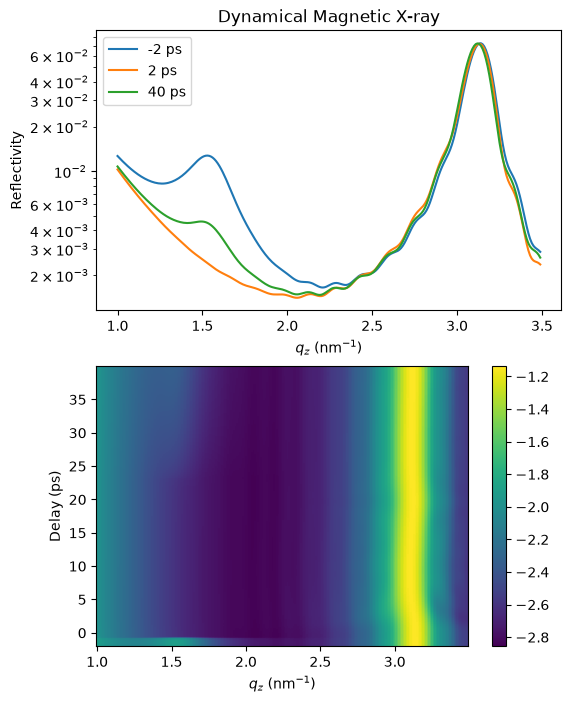

In [27]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
plt.semilogy(dyn_mag.qz[0, :].to("1/nm"), res_inhom.R[0, 0, :], label=np.round(delays[0]))
plt.semilogy(dyn_mag.qz[0, :].to("1/nm"), res_inhom.R[40, 0, :], label=np.round(delays[40]))
plt.semilogy(dyn_mag.qz[0, :].to("1/nm"), res_inhom.R[-1, 0, :], label=np.round(delays[-1]))

plt.xlabel("$q_z$ (nm$^{-1}$)")
plt.ylabel("Reflectivity")
plt.legend()
plt.title("Dynamical Magnetic X-ray")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    dyn_mag.qz[0, :].to("1/nm").magnitude,
    res_inhom.quantity("delays").to("ps"),
    np.log10(res_inhom.R[:, 0, :]),
    shading="auto",
)

plt.ylabel("Delay (ps)")
plt.xlabel("$q_z$ (nm$^{-1}$)")
plt.colorbar()
plt.show()

## Parallel Magnetic X-ray Reflectivity

The delays can be calculated in parallel with [Dask](https://docs.dask.org/en/latest/), as for {py:class}`XrayDyn <udkm1Dsim.simulations.scattering.dynamical.XrayDyn>`, see the [dynamical X-ray scattering example](#example_dynamical_xray), which requires the `parallel` option, e.g. by `pip install udkm1Dsim[parallel]`.

In [ ]:
try:
    from dask.distributed import Client

    client = Client(threads_per_worker=1)  # one worker per CPU core
    res_inhom_par = dyn_mag.inhomogeneous_reflectivity_transmissivity(
        strain_map=res_strain,
        magnetization_map=magnetization_map,
        calc_type="parallel",
        dask_client=client,
    )
    client.close()
except ImportError:
    pass

/home/schick/.local/share/mamba/envs/udkm1Dsim/lib/python3.12/site-packages/distributed/node.py:188: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 41129 instead
  warnings.warn(


Calculating _inhomogeneous_reflectivity_transmissivity_Elzo_ ...


Progress:   0%|          | 0/420 [00:00<?, ?it/s]

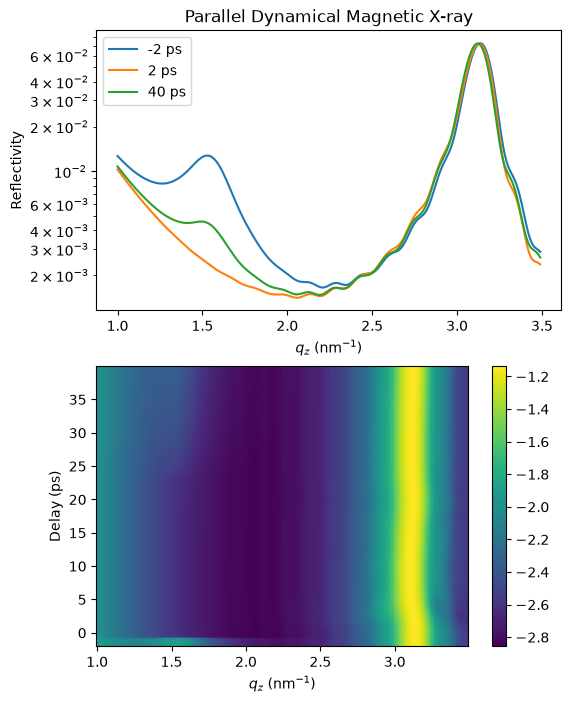

In [ ]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
plt.semilogy(dyn_mag.qz[0, :].to("1/nm"), res_inhom_par.R[0, 0, :], label=np.round(delays[0]))
plt.semilogy(dyn_mag.qz[0, :].to("1/nm"), res_inhom_par.R[40, 0, :], label=np.round(delays[40]))
plt.semilogy(dyn_mag.qz[0, :].to("1/nm"), res_inhom_par.R[-1, 0, :], label=np.round(delays[-1]))

plt.xlabel("$q_z$ (nm$^{-1}$)")
plt.ylabel("Reflectivity")
plt.legend()
plt.title("Parallel Dynamical Magnetic X-ray")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    dyn_mag.qz[0, :].to("1/nm").magnitude,
    delays.to("ps").magnitude,
    np.log10(res_inhom_par.R[:, 0, :]),
    shading="auto",
)

plt.ylabel("Delay (ps)")
plt.xlabel("$q_z$ (nm$^{-1}$)")
plt.colorbar()
plt.show()

## Gallery Plot

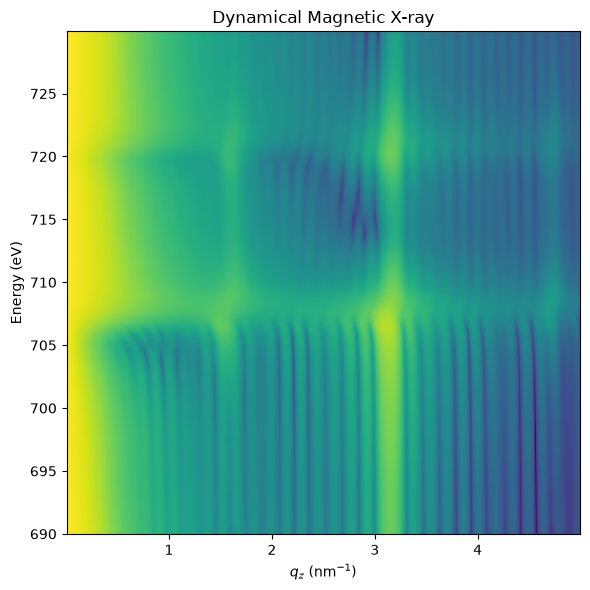

In [ ]:
dyn_mag.energy = np.r_[690:730:0.1] * u.eV  # set the energy range
dyn_mag.qz = np.r_[0.01:5:0.01] / u.nm  # qz range

plt.figure(figsize=[6, 6])
plt.pcolormesh(
    dyn_mag.qz[0, :].to("1/nm").magnitude,
    dyn_mag.energy.magnitude,
    np.log10(res_gallery.R[:, :]),
    shading="auto",
)
plt.title("Dynamical Magnetic X-ray")
plt.ylabel("Energy (eV)")
plt.xlabel("$q_z$ (nm$^{-1}$)")

plt.tight_layout()
plt.show()